In [17]:

import io
import re
import time
import hashlib
from collections import deque
from datetime import datetime, timezone
from urllib.parse import urljoin, urlsplit, urlunsplit, urldefrag

import pandas as pd
import matplotlib.pyplot as plt
import requests
import pymupdf
from bs4 import BeautifulSoup
from IPython.display import display
from pathlib import Path

USCITYURL_CSV = (
    "https://raw.githubusercontent.com/caimeng2/"
    "UScityURL/master/UScityURL.csv"
)

# Same limits as teammate's Orlando notebook
MAX_PAGES_TO_CRAWL = 60
MAX_DOCUMENTS_TO_ANALYZE = 15
REQUEST_TIMEOUT = 15
REQUEST_DELAY = 0.15

CITIES = [
    ("Orlando", "Florida"),
    ("Miami", "Florida"),
    ("Seattle", "Washington")
]

HEADERS = {
    "User-Agent": "CMSE495-USCityURL-Demo/1.0 (educational research)"
}

session = requests.Session()
session.headers.update(HEADERS)

Path("outputs").mkdir(exist_ok=True)

print("Comparison settings ready.")


Comparison settings ready.


In [18]:
# Load UScityURL


cities = pd.read_csv(USCITYURL_CSV)

selected_cities = []

for city, state in CITIES:

    match = cities[
        cities["MUNICIPALITY"].astype(str).str.strip().str.casefold().eq(city.casefold())
        & cities["STATE"].astype(str).str.strip().str.casefold().eq(state.casefold())
    ]

    if match.empty:
        print(f"Not found: {city}, {state}")
        continue

    selected_cities.append({
        "municipality": city,
        "state": state,
        "base_url": match.iloc[0]["WEBSITE_URL"]
    })

city_df = pd.DataFrame(selected_cities)

display(city_df)


,municipality,state,base_url
0,Orlando,Florida,https://www.orlando.gov/
1,Miami,Florida,https://www.miamigov.com/
2,Seattle,Washington,https://www.seattle.gov/


In [35]:
# reuse crawler


RESILIENCE_KEYWORDS = [
    "resilience", "resiliency", "hazard", "mitigation",
    "climate", "adaptation", "emergency", "flood",
    "hurricane", "storm", "sustainability",
    "future ready", "comprehensive plan", "master plan"
]

PLANNING_PHRASES = [
    "resilience plan",
    "comprehensive plan",
    "hazard mitigation",
    "climate action"
]

SKIP_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".gif",
    ".svg", ".zip", ".mp4", ".mp3"
)

SKIP_HOSTS = {
    "facebook.com", "www.facebook.com",
    "twitter.com", "x.com", "maps.google.com"
}

def normalize_url(url):
    clean_url, _ = urldefrag(str(url))
    parts = urlsplit(clean_url)

    return urlunsplit((
        parts.scheme.lower(),
        parts.netloc.lower(),
        parts.path or "/",
        "",
        ""
    ))

def fetch(url):
    try:
        response = session.get(
            url,
            timeout=REQUEST_TIMEOUT,
            allow_redirects=True
        )
        response.raise_for_status()
        return response, None

    except requests.RequestException as error:
        return None, f"{type(error).__name__}: {error}"

def page_links(page_url, html):
    soup = BeautifulSoup(html, "html.parser")
    found = []

    for anchor in soup.find_all("a", href=True):
        raw_url = anchor["href"].strip()

        if raw_url.startswith(
            ("mailto:", "tel:", "javascript:")
        ):
            continue

        full_url = normalize_url(
            urljoin(page_url, raw_url)
        )

        parts = urlsplit(full_url)

        if parts.scheme not in ("http", "https"):
            continue

        if parts.netloc in SKIP_HOSTS:
            continue

        if parts.path.lower().endswith(SKIP_EXTENSIONS):
            continue

        found.append({
            "anchor_text": anchor.get_text(" ", strip=True),
            "url": full_url
        })

    return found


In [37]:
# Reusable city crawler

def crawl_city(city, state, base_url):

    print(f"\nCrawling {city}, {state}")
    print("Website:", base_url)

    official_host = urlsplit(base_url).netloc.lower()

    to_visit = deque([normalize_url(base_url)])
    visited = set()
    collected_links = []
    failures = []

    while to_visit and len(visited) < MAX_PAGES_TO_CRAWL:

        current_url = to_visit.popleft()

        if current_url in visited:
            continue

        visited.add(current_url)

        response, error = fetch(current_url)

        if error:
            failures.append({
                "municipality": city,
                "url": current_url,
                "error": error
            })
            continue

        content_type = response.headers.get(
            "Content-Type", ""
        ).lower()

        # Only parse HTML pages for links
        if "html" not in content_type:
            continue

        links = page_links(response.url, response.text)
        collected_links.extend(links)

        for item in links:

            link_host = urlsplit(
                item["url"]
            ).netloc.lower()

            if (
                link_host == official_host
                and item["url"] not in visited
                and item["url"] not in to_visit
            ):
                to_visit.append(item["url"])

        time.sleep(REQUEST_DELAY)

    
    # Create DataFrame with expected columns
    columns = ["anchor_text", "url"]

    links_df = pd.DataFrame(
        collected_links, columns=columns
    ).drop_duplicates(subset="url")

    # Handle websites where no links were collected
    if links_df.empty:

        print(f"No links collected for {city}.")

        empty_candidates = pd.DataFrame(columns=[
            "anchor_text",
            "url",
            "search_text",
            "keywords_found",
            "relevance_score"
        ])

        return {
            "visited": visited,
            "links": links_df,
            "candidates": empty_candidates,
            "failures": failures
        }

    # Keep links from the official website
    links_df = links_df[
        links_df["url"].apply(
            lambda url: urlsplit(url).netloc.lower()
            == official_host
        )
    ].copy()

    # Handle cases where all links are filtered out
    if links_df.empty:

        print(f"No same-domain links for {city}.")

        empty_candidates = pd.DataFrame(columns=[
            "anchor_text",
            "url",
            "search_text",
            "keywords_found",
            "relevance_score"
        ])

        return {
            "visited": visited,
            "links": links_df,
            "candidates": empty_candidates,
            "failures": failures
        }

    # Keyword matching
    links_df["search_text"] = (
        links_df["anchor_text"].fillna("")
        + " "
        + links_df["url"]
    ).str.casefold()

    links_df["keywords_found"] = (
        links_df["search_text"].apply(
            lambda text: [
                keyword
                for keyword in RESILIENCE_KEYWORDS
                if keyword in text
            ]
        )
    )

    relevant_links = links_df[
        links_df["keywords_found"].str.len() > 0
    ].copy()

    relevant_links["relevance_score"] = (
        relevant_links.apply(
            lambda row: len(row["keywords_found"])
            + 3 * sum(
                phrase in row["search_text"]
                for phrase in PLANNING_PHRASES
            ),
            axis=1
        )
        if not relevant_links.empty
        else pd.Series(dtype="int64")
    )

    relevant_links = relevant_links.sort_values(
        ["relevance_score", "anchor_text"],
        ascending=[False, True]
    ).reset_index(drop=True)

    print("Pages visited:", len(visited))
    print("Links collected:", len(links_df))
    print("Candidate links:", len(relevant_links))
    print("Crawl failures:", len(failures))

    return {
        "visited": visited,
        "links": links_df,
        "candidates": relevant_links,
        "failures": failures
    }


    links_df = links_df[
        links_df["url"].apply(
            lambda url: urlsplit(url).netloc.lower()
            == official_host
        )
    ].copy()

    links_df["search_text"] = (
        links_df["anchor_text"].fillna("")
        + " "
        + links_df["url"]
    ).str.casefold()

    links_df["keywords_found"] = (
        links_df["search_text"].apply(
            lambda text: [
                keyword
                for keyword in RESILIENCE_KEYWORDS
                if keyword in text
            ]
        )
    )

    relevant_links = links_df[
        links_df["keywords_found"].str.len() > 0
    ].copy()

    relevant_links["relevance_score"] = (
        relevant_links.apply(
            lambda row: len(row["keywords_found"])
            + 3 * sum(
                phrase in row["search_text"]
                for phrase in PLANNING_PHRASES
            ),
            axis=1
        )
    )

    relevant_links = relevant_links.sort_values(
        ["relevance_score", "anchor_text"],
        ascending=[False, True]
    ).reset_index(drop=True)

    print("Pages visited:", len(visited))
    print("Links collected:", len(links_df))
    print("Candidate links:", len(relevant_links))
    print("Crawl failures:", len(failures))

    return {
        "visited": visited,
        "links": links_df,
        "candidates": relevant_links,
        "failures": failures
    }


In [21]:

def clean_text(text):
    return re.sub(r"\s+", " ", text or "").strip()

def extract_document(row):

    response, error = fetch(row["url"])

    result = {
        "title": row["anchor_text"] or row["url"],
        "url": row["url"],
        "keywords_found": row["keywords_found"],
        "status": "failed" if error else "ok",
        "format": "unknown",
        "extraction_method": "none",
        "error": error,
        "text": ""
    }

    if response is None:
        return result

    content_type = response.headers.get(
        "Content-Type", ""
    ).lower()

    is_pdf = (
        "pdf" in content_type
        or response.content.startswith(b"%PDF")
    )

    try:
        if is_pdf:
            with pymupdf.open(
                stream=io.BytesIO(response.content),
                filetype="pdf"
            ) as pdf:

                text = " ".join(
                    page.get_text("text")
                    for page in pdf
                )

            result["format"] = "PDF"
            result["extraction_method"] = "PyMuPDF"

        elif "html" in content_type:
            soup = BeautifulSoup(
                response.text, "html.parser"
            )

            for tag in soup([
                "script", "style", "nav",
                "header", "footer"
            ]):
                tag.decompose()

            main = (
                soup.find("main")
                or soup.find("article")
                or soup.body
                or soup
            )

            text = main.get_text(" ", strip=True)

            result["format"] = "HTML"
            result["extraction_method"] = "BeautifulSoup"

        else:
            result["status"] = "unsupported"
            result["error"] = content_type
            return result

        result["text"] = clean_text(text)

    except Exception as e:
        result["status"] = "failed"
        result["error"] = str(e)

    return result


In [22]:

all_results = {}
all_documents = []
all_failures = []
comparison_rows = []

for _, city_row in city_df.iterrows():

    city = city_row["municipality"]
    state = city_row["state"]
    base_url = city_row["base_url"]

    crawl = crawl_city(
        city, state, base_url
    )

    all_results[city] = crawl
    all_failures.extend(crawl["failures"])

    candidates = crawl["candidates"]

    sample = candidates.head(
        MAX_DOCUMENTS_TO_ANALYZE
    )

    city_documents = []

    for _, link in sample.iterrows():

        document = extract_document(link)

        document["municipality"] = city
        document["state"] = state
        document["collection_date"] = (
            datetime.now(timezone.utc).isoformat()
        )

        document["word_count"] = len(
            re.findall(
                r"\b[\w'-]+\b",
                document["text"]
            )
        )

        document["quality"] = (
            "Failed" if document["word_count"] == 0
            else "Short - review"
            if document["word_count"] < 100
            else "Usable"
        )

        city_documents.append(document)

        time.sleep(REQUEST_DELAY)

    city_docs_df = pd.DataFrame(city_documents)

    if not city_docs_df.empty:

        city_docs_df["normalized_text"] = (
            city_docs_df["text"]
            .str.casefold()
            .str.replace(r"\s+", " ", regex=True)
        )

        city_docs_df["exact_duplicate"] = (
            city_docs_df["normalized_text"]
            .duplicated(keep="first")
        )

        usable = city_docs_df[
            (city_docs_df["quality"] == "Usable")
            & (~city_docs_df["exact_duplicate"])
        ]

        all_documents.extend(
            city_docs_df.to_dict("records")
        )

        usable_count = len(usable)
        total_words = int(usable["word_count"].sum())

        duplicate_count = int(
            city_docs_df["exact_duplicate"].sum()
        )

    else:
        usable_count = 0
        total_words = 0
        duplicate_count = 0

    comparison_rows.append({
        "Municipality": city,
        "State": state,
        "Pages_Visited": len(crawl["visited"]),
        "Unique_Links": len(crawl["links"]),
        "Candidate_Links": len(candidates),
        "Documents_Attempted": len(city_documents),
        "Usable_Documents": usable_count,
        "Exact_Duplicates": duplicate_count,
        "Total_Usable_Words": total_words,
        "Crawl_Failures": len(crawl["failures"])
    })

comparison_df = pd.DataFrame(comparison_rows)
documents_df = pd.DataFrame(all_documents)
failures_df = pd.DataFrame(
    all_failures,
    columns=["municipality", "url", "error"]
)

display(comparison_df)



Crawling Orlando, Florida
Website: https://www.orlando.gov/
Pages visited: 60
Links collected: 734
Candidate links: 21
Crawl failures: 2

Crawling Miami, Florida
Website: https://www.miamigov.com/
No links collected for Miami.

Crawling Seattle, Washington
Website: https://www.seattle.gov/
Pages visited: 60
Links collected: 4781
Candidate links: 154
Crawl failures: 0


,Municipality,State,Pages_Visited,Unique_Links,Candidate_Links,Documents_Attempted,Usable_Documents,Exact_Duplicates,Total_Usable_Words,Crawl_Failures
0,Orlando,Florida,60,734,21,15,12,0,6580,2
1,Miami,Florida,1,0,0,0,0,0,0,1
2,Seattle,Washington,60,4781,154,15,11,3,8575,0


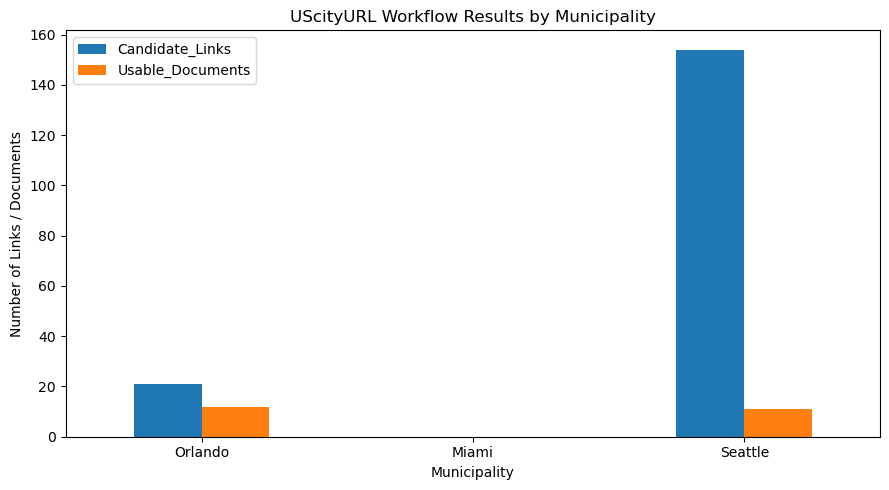

In [23]:
# compare extracted text volume
comparison_df.plot(
    x="Municipality",
    y=[
        "Candidate_Links",
        "Usable_Documents"
    ],
    kind="bar",
    figsize=(9, 5)
)

plt.title("UScityURL Workflow Results by Municipality")
plt.ylabel("Number of Links / Documents")
plt.xlabel("Municipality")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


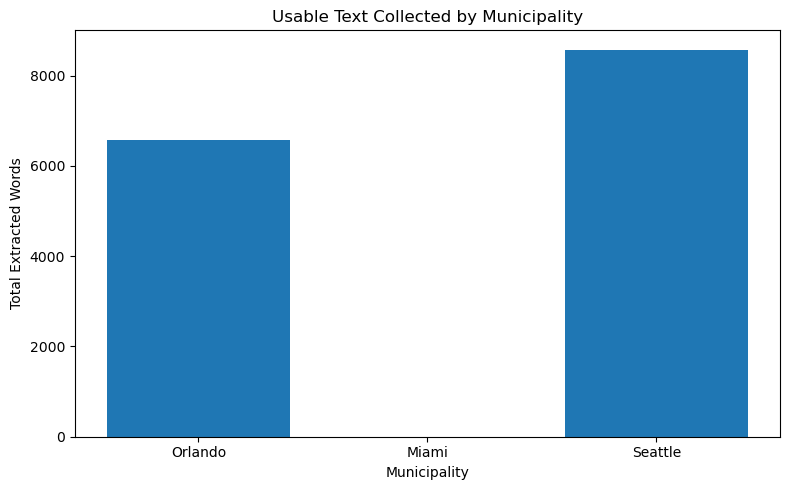

In [24]:
# Topic comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Municipality"],
    comparison_df["Total_Usable_Words"]
)

plt.title("Usable Text Collected by Municipality")
plt.xlabel("Municipality")
plt.ylabel("Total Extracted Words")
plt.tight_layout()
plt.show()


Topic,climate,emergency,flood,heat,housing,hurricane,infrastructure,mitigation,resilience,storm,sustainability
Municipality,,,,,,,,,,,
Orlando,2,19,29,2,29,7,3,5,20,25,1
Seattle,19,22,10,0,18,0,1,3,1,23,2


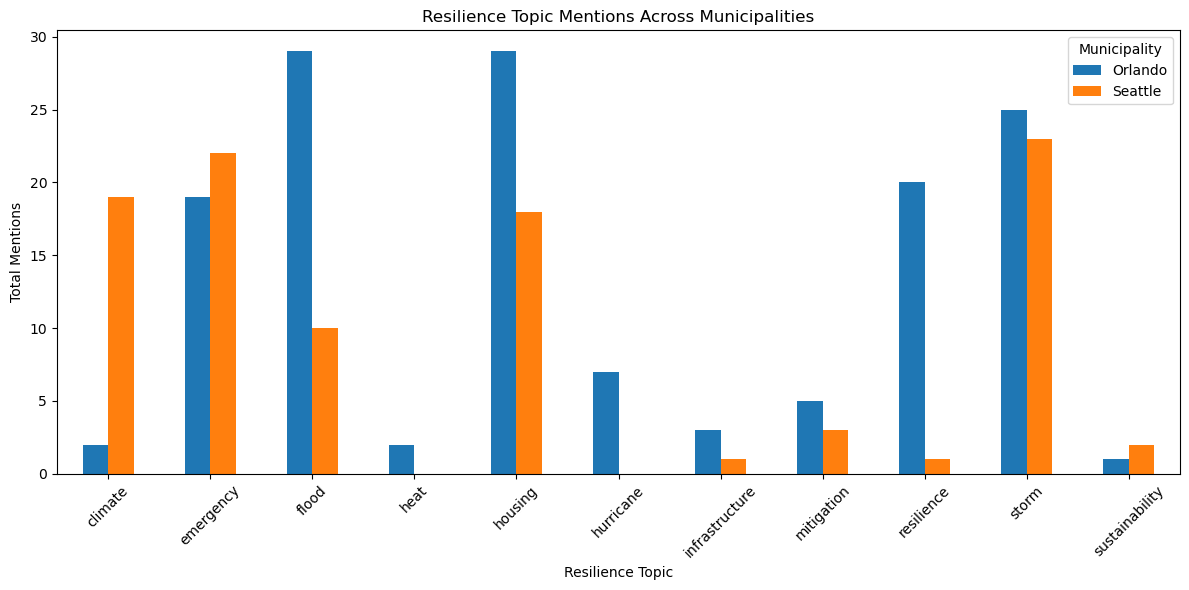

In [9]:

TOPICS = [
    "resilience", "climate", "flood",
    "hurricane", "storm", "heat",
    "housing", "infrastructure",
    "emergency", "mitigation",
    "sustainability"
]

def count_topic(text, topic):
    pattern = rf"(?<!\w){re.escape(topic)}(?!\w)"

    return len(re.findall(
        pattern,
        text or "",
        flags=re.IGNORECASE
    ))

topic_rows = []

if not documents_df.empty:

    usable_documents = documents_df[
        (documents_df["quality"] == "Usable")
        & (~documents_df["exact_duplicate"])
    ].copy()

    for _, document in usable_documents.iterrows():

        for topic in TOPICS:

            count = count_topic(
                document["text"], topic
            )

            topic_rows.append({
                "Municipality": document["municipality"],
                "Topic": topic,
                "Mentions": count,
                "Word_Count": document["word_count"]
            })

topic_df = pd.DataFrame(topic_rows)

if not topic_df.empty:

    topic_summary = topic_df.groupby(
        ["Municipality", "Topic"]
    )["Mentions"].sum().unstack(fill_value=0)

    display(topic_summary)

    topic_summary.T.plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title(
        "Resilience Topic Mentions Across Municipalities"
    )
    plt.ylabel("Total Mentions")
    plt.xlabel("Resilience Topic")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("No usable documents available for topic analysis.")


Topic,climate,emergency,flood,heat,housing,hurricane,infrastructure,mitigation,resilience,storm,sustainability
Municipality,,,,,,,,,,,
Orlando,0.30,2.89,4.41,0.3,4.41,1.06,0.46,0.76,3.04,3.80,0.15
Seattle,2.22,2.57,1.17,0.0,2.10,0.00,0.12,0.35,0.12,2.68,0.23


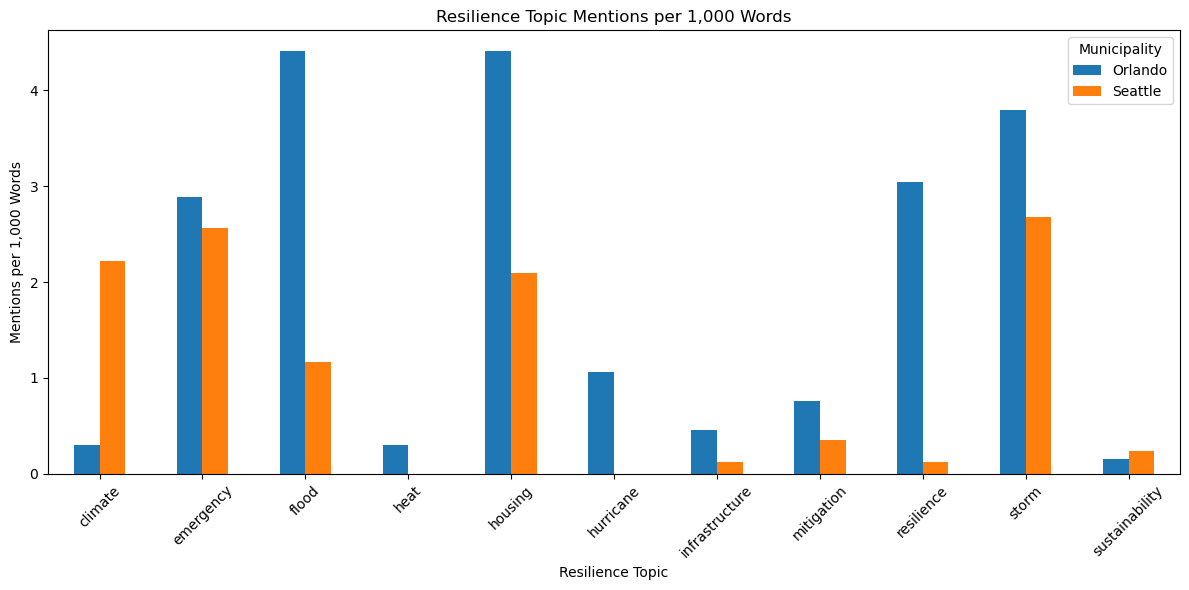

In [10]:
# Total usable words per municipality
word_totals = usable_documents.groupby(
    "municipality"
)["word_count"].sum()

# Normalize topic counts per 1,000 words
normalized_topics = topic_summary.div(
    word_totals, axis=0
) * 1000

display(normalized_topics.round(2))

# Plot normalized frequencies
normalized_topics.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Resilience Topic Mentions per 1,000 Words"
)
plt.xlabel("Resilience Topic")
plt.ylabel("Mentions per 1,000 Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()